# Assignment 4: PCA
Date: 

Report produced by:  
COMP 3705 Group 3

## Load the data and inspect the header

In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df_cc = pd.read_csv("CC GENERAL.CSV")
df_cc_clean = df_cc.copy()
df_cc_clean.head(10)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.000000,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,C10007,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.000000,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,C10008,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.000000,0,12,2300.0,679.065082,532.033990,0.000000,12
8,C10009,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.000000,0,5,7000.0,688.278568,311.963409,0.000000,12
9,C10010,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.000000,0,3,11000.0,1164.770591,100.302262,0.000000,12


In [26]:
df_cc_clean.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [27]:
cc_columns = df_cc_clean.columns.to_list()
print(cc_columns)

['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']


## Observations 
### Meaning of the Columns
*Column Meanings Aquired From Source*  
https://www.kaggle.com/datasets/arjunbhasin2013/ccdata  
- **CUST_ID** : Identification of Credit Card holder (Categorical)
- **BALANCE** : Balance amount left in their account to make purchases (
- **BALANCE_FREQUENCY** : How frequently the Balance is updated, score between 0 and 1 (1 = frequently updated, 0 = not frequently updated)
- **PURCHASES** : Amount of purchases made from account
- **ONEOFF_PURCHASES** : Maximum purchase amount done in one-go
- **INSTALLMENTS_PURCHASES** : Amount of purchase done in installment
- **CASH_ADVANCE** : Cash in advance given by the user
- **PURCHASES_FREQUENCY** : How frequently the Purchases are being made, score between 0 and 1 (1 = frequently purchased, 0 = not frequently purchased)
- **ONEOFF_PURCHASES_FREQUENCY** : How frequently Purchases are happening in one-go (1 = frequently purchased, 0 = not frequently purchased)
- **PURCHASES_INSTALLMENTS_FREQUENCY** : How frequently purchases in installments are being done (1 = frequently done, 0 = not frequently done)
- **CASH_ADVANCE_FREQUENCY** : How frequently the cash in advance being paid
- **CASH_ADVANCE_TRX** : Number of Transactions made with "Cash in Advanced"
- **PURCHASES_TRX** : Numbe of purchase transactions made
- **CREDIT_LIMIT** : Limit of Credit Card for user
- **PAYMENTS** : Amount of Payment done by user
- **MINIMUM_PAYMENTS** : Minimum amount of payments made by user
- **PRC_FULL_PAYMENT** : Percent of full payment paid by user
- **TENURE** : Tenure of credit card service for user

### Observations on Column Statistics

As the column `CUST_ID` is an identifier column for the dataset, we will check if it's entirely unique and drop it if it is.

The column BALANCE appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 0.000 and 128.282. It has an IQR of (128.282, 2054.140) with a median of 873.385 and mean of 1564.475. And finally, the last 25% of the data falls between the values of 2054.140 and 19043.139. This shows that most customers have lower balances, while a few customers have very high balances.
 
The column PURCHASES appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 0.000 and 39.635. It has an IQR of (39.635, 1110.130) with a median of 361.280 and mean of 1003.205. And finally, the last 25% of the data falls between the values of 1110.130 and 49039.570. This shows that most customers have lower purchase amounts, while a few customers make very large purchases.

The column PURCHASES appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 0.000 and 39.635. It has an IQR of (39.635, 1110.130) with a median of 361.280 and mean of 1003.205. And finally, the last 25% of the data falls between the values of 1110.130 and 49039.570. This shows that most customers have lower purchase amounts, while a few customers make very large purchases.

The column ONEOFF_PURCHASES appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 0.000 and 0.000. It has an IQR of (0.000, 577.405) with a median of 38.000 and mean of 592.437. And finally, the last 25% of the data falls between the values of 577.405 and 40761.250. This shows that many customers make little or no one-off purchases, while a few customers make very large one-off purchases.

The column CHSH_ADVANCE appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 0.000 and 0.000. It has an IQR of (0.000, 1113.821) with a median of 0.000 and mean of 978.871. And finally, the last 25% of the data falls between the values of 1113.821 and 47137.212. This shows that at least half of the customers have no cash advances, while some customers have very high cash advance amounts. 

The column CRRDIT_LIMIT appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 50.000 and 1600.000. It has an IQR of (1600.000, 6500.000) with a median of 3000.000 and mean of 4494.449. And finally, the last 25% of the data falls between the values of 6500.000 and 30000.000. This shows that most customers have lower credit limits, while a smaller number of customers have very high credit limits.

The column PAYMENTS appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 0.000 and 383.276. It has an IQR of (383.276, 1901.134) with a median of 856.902 and mean of 1733.144. And finally, the last 25% of the data falls between the values of 1901.134 and 50721.483. This shows that most customers make smaller payments, while a few customers make very large payments.

The column `MINIMUM_PAYMENTS` appears to have a right-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 0.019 and 169.124. It has an IQR of (169.124, 825.485) with a median of 312.344 and mean of 864.207. And finally, the last 25% of the data falls between the values of 825.485 and 76406.208. This heavily demonstrates right-skewedness in the columns distribution.

The column TENURE appears to have a left-skewed distribution. This can be observed from the IQR values as well as the minimum and maximum within the column. The first 25% of data falls between a range of 6.000 and 12.000. It has an IQR of (12.000, 12.000) with a median of 12.000 and mean of 11.517. And finally, the last 25% of the data falls between the values of 12.000 and 12.000. This shows that most customers have a tenure of 12 months, while a smaller number of customers have a tenure between 6 and 11 months. This suggests that most customers have been with the credit card company for the full 12-month period represented in the dataset.

From our observations, the majority of the data is right skewed, the only exception to this are the columns of `TENURE` and `BALANCE_FREQUENCY` which show left-skewedness given their IQR is (12, 12) and (0.889, 1) with a max of 12 and 1 respectively, or the frequency columns of `PURCHASES_FREQUENCY` and `PURCHASES_INSTALLMENTS_FREQUENCY` which appear relatively balance, given that for `PURCHASES_FREQUENCY` the mean (0.490) lines up with the median (0.5) and in `PURCHASES_INSTALLMENTS_FREQUENCY` the mean (0.364) is still relatively even though the range from the median (0.167) to 75% (0.167, 1) is much greater than from the 25% mark to the median (0, 0.167).

### Drop Unnecessary Columns

In [28]:
print(df_cc_clean["CUST_ID"].is_unique)
if df_cc_clean["CUST_ID"].is_unique == True:
    df_cc_clean = df_cc_clean.drop(columns="CUST_ID")

True


### Check Dtypes, Missing Values, & Duplicate Rows

In [29]:
df_cc_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 17 columns):
BALANCE                             8950 non-null float64
BALANCE_FREQUENCY                   8950 non-null float64
PURCHASES                           8950 non-null float64
ONEOFF_PURCHASES                    8950 non-null float64
INSTALLMENTS_PURCHASES              8950 non-null float64
CASH_ADVANCE                        8950 non-null float64
PURCHASES_FREQUENCY                 8950 non-null float64
ONEOFF_PURCHASES_FREQUENCY          8950 non-null float64
PURCHASES_INSTALLMENTS_FREQUENCY    8950 non-null float64
CASH_ADVANCE_FREQUENCY              8950 non-null float64
CASH_ADVANCE_TRX                    8950 non-null int64
PURCHASES_TRX                       8950 non-null int64
CREDIT_LIMIT                        8949 non-null float64
PAYMENTS                            8950 non-null float64
MINIMUM_PAYMENTS                    8637 non-null float64
PRC_FULL_PAYMENT           

### Data Type Observations
The dataset contains 8,950 rows and 17 columns, all of which are numeric (14 `float64` and 3 `int64`), so no categorical encoding is needed. The `float64` columns are split into monetary values [`BALANCE`, `PURCHASES`, `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `CASH_ADVANCE`, `CREDIT_LIMIT`, `PAYMENTS`, `MINIMUM_PAYMENTS`] and frequency scored between 0 and 1 [`BALANCE_FREQUENCY`, `PURCHASES_FREQUENCY`, `ONEOFF_PURCHASES_FREQUENCY`, `PURCHASES_INSTALLMENTS_FREQUENCY`, `CASH_ADVANCE_FREQUENCY`, `PRC_FULL_PAYMENT`].  
The three `int64` columns are whole-number counts: `CASH_ADVANCE_TRX`, `PURCHASES_TRX` and `TENURE`.

All columns are of an appropriate data type for the information they contain.

### Missing Value Handling

In [30]:
print(df_cc_clean.isna().sum())
print(df_cc_clean.isna().mean()*100)

BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64
BALANCE                             0.000000
BALANCE_FREQUENCY                   0.000000
PURCHASES                           0.000000
ONEOFF_PURCHASES                    0.000000
INSTALLMENTS_PURCHASES              0.000000
CASH_ADVANCE                        0.000000
PURCHASES_FREQUENCY                 0

In [31]:
print(df_cc_clean[df_cc_clean["MINIMUM_PAYMENTS"]==0].count())

BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64


### Missing Value Analysis
As the column `CREDIT_LIMIT` has only 1 missing value out of 8950 rows, the row containing this missing value will be dropped.

For the missing values in `MINIMUM_PAYMENTS`, We decided to handle them in two steps. The first checks whether that account has any value greater than 0 in `PAYMENTS`. If a client has no money owed, there is unlikely to be any minimum payments made.  
For the remaining missing values, we decided to set them equal to the column's median value since its distribution was observed to be right-skewed. 

In [32]:
df_cc_clean = df_cc_clean.drop(df_cc_clean[df_cc_clean["CREDIT_LIMIT"].isna()==True].index)

df_cc_clean.loc[df_cc_clean['MINIMUM_PAYMENTS'].isna() & (df_cc_clean['PAYMENTS'] == 0), 'MINIMUM_PAYMENTS'] = 0
minimum_payments_median = df_cc_clean['MINIMUM_PAYMENTS'].median()
df_cc_clean.loc[df_cc_clean['MINIMUM_PAYMENTS'].isna() & (df_cc_clean['PAYMENTS'] > 0), 'MINIMUM_PAYMENTS'] = minimum_payments_median

print(df_cc_clean.isna().sum())

BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64


### Check Duplicated Rows

In [33]:
df_cc_clean.duplicated(keep=False).sum()

0

As there are no duplicated rows and we've finished cleaning the missing values, we can now send the data for scaling and modeling

### Findings and Cleaning

**1. Data Structure and Types**  
- The dataset contains 8,950 rows and 18 columns, one of which is categorical and not needed for modeling.
- All 18 columns have the correct data types.

**2. Dropped Columns**
- The column `CUST_ID` was removed as it is entirely unique and represents a unique identifier for each account.

**3. Missing values**  
- Only two columns have missing values: `CREDIT_LIMIT` and `MINIMUM_PAYMENTS`
    - `CREDIT_LIMIT` contained 1 missing value - Approximately 0.01% of the data.
    - `MINIMUM_PAYMENTS` contained 313 missing values - Approximately 3.50% of the data

**4. Duplicate Data Entries**  
- No duplicate entries were found in the data.

**5. Cleaning Steps**:
- `CREDIT_LIMIT`:
    - Dropped since only 1 row out of 8950 contained a missing value.
    - Credit limit can't be reliably estimated from other columns.
- `MINIMUM_PAYMENTS`:
    - Clients with a value of 0 in `PAYMENTS` required no `MINIMUM_PAYMENTS` and so the value was set to 0.  
    - The rest of the values were replaced with the median as the distribution was Right-Skewed.
- These changes were made in attempt to preserve the data quality and integrity as much as possible.

**Result:**  
    After cleaning the dataset, we reduced the number of rows from 8,950 to 8,949 and the number of columns from 18 to 17. We removed the CUST_ID column because it was only used to identify customers and was not needed for modeling.
We also handled the missing values in CREDIT_LIMIT and MINIMUM_PAYMENTS. We removed the one row with a missing credit limit and filled the missing minimum payments using zero or the median based on our cleaning conditions. We checked the dataset again and confirmed that there were no remaining missing values or duplicate rows.
The dataset now contains 8,949 customer records with 17 numerical columns. All the columns are ready for scaling using MinMaxScaler and PCA. After scaling, we can use the data to build our clustering models and compare how well they group customers with similar credit card activities.
 

## Data Visualizations

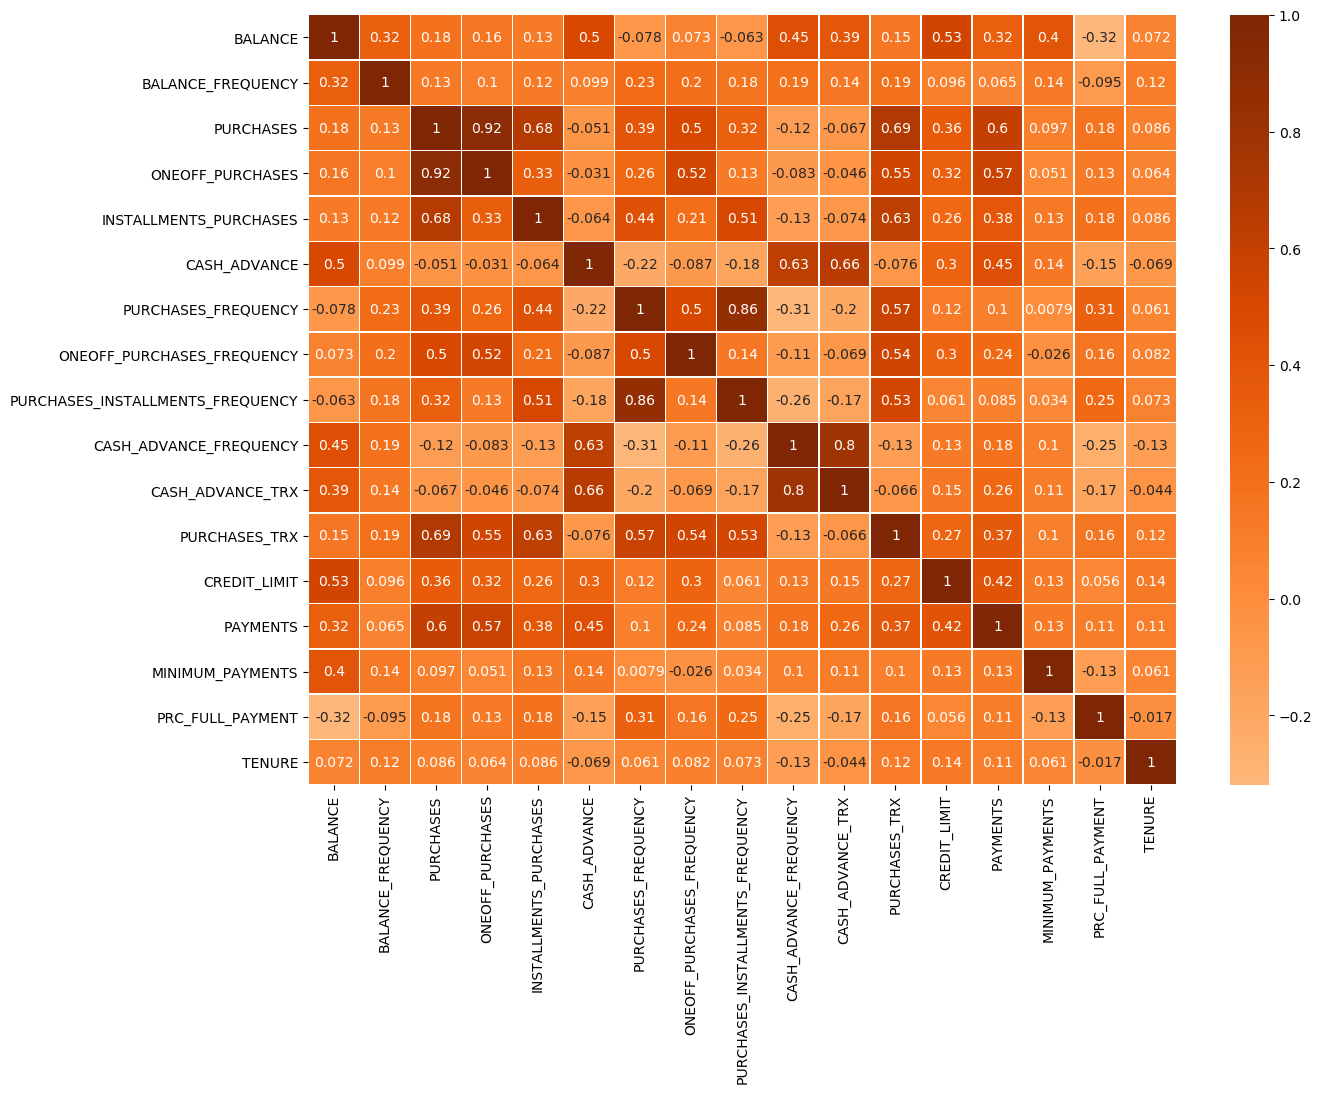

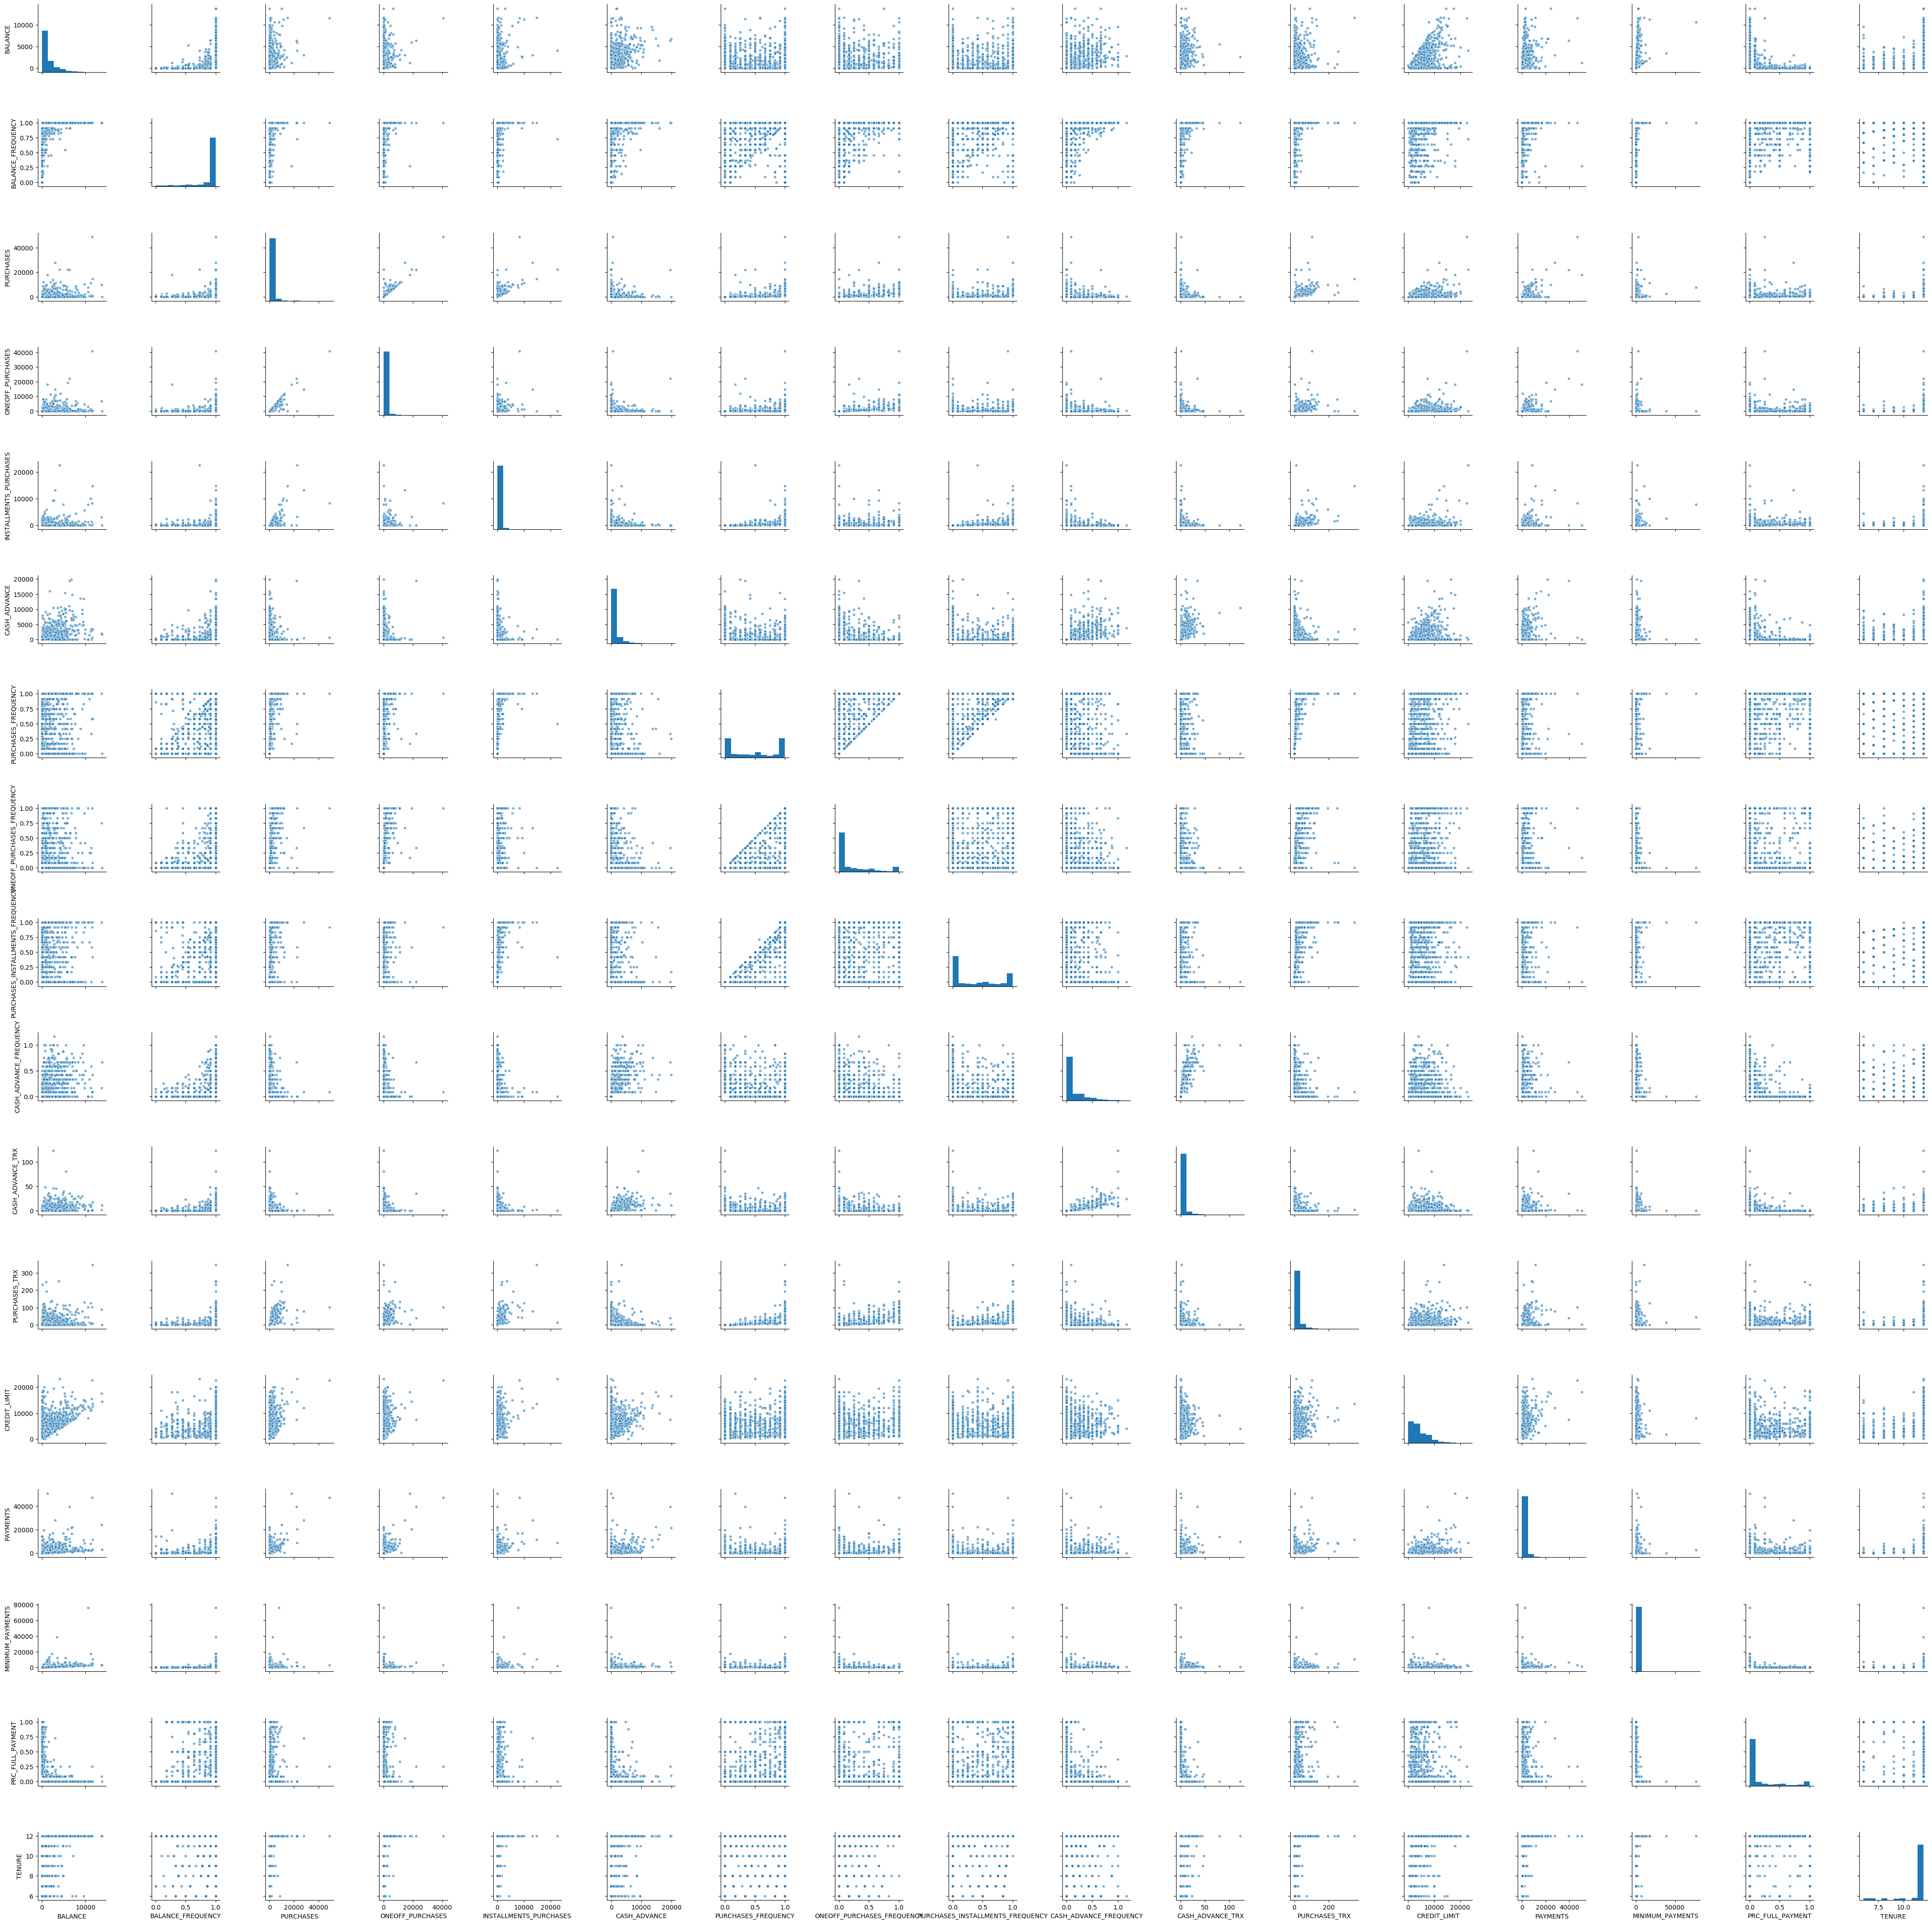

In [34]:
plt.figure(figsize=(14, 10))

# Plot a heatmap of the features correlation
sns.heatmap(df_cc_clean.corr(), annot=True, cmap="Oranges", center=0, linewidths=0.3)
plt.title("")
plt.show()

# Create a pairplot using a random sample of points (1500)
df_sample = df_cc_clean.sample(n=1500, random_state=42)
sns.pairplot(df_sample,diag_kind="hist",plot_kws={"alpha": 0.6, "s": 20})
plt.suptitle("", y=1.01)
plt.show()

## Correlation Matrix & Pairplot Observations

**Strong positive correlations:**
- `PURCHASES` & `ONEOFF_PURCHASES` (**0.92**): most purchases came from from one-off purchases.
- `PURCHASES_FREQUENCY` & `PURCHASES_INSTALLMENTS_FREQUENCY` (**0.86**): customers with high purchase frquency usually buy in installments.
- `PURCHASES` with `PURCHASES_TRX` (0.69), `INSTALLMENTS_PURCHASES` (0.68) and `PAYMENTS` (0.60): customers who typically spend more have  more transactions and pay back more.
- `BALANCE` & `CREDIT_LIMIT` (**0.53**): higher credit limits usually go with higher balances.

**Negative correlations:**
- `BALANCE` & `PRC_FULL_PAYMENT` (−0.32): customers who usually make their payments in full keep lower balances.
- `PURCHASES_FREQUENCY` & `CASH_ADVANCE_FREQUENCY` (−0.31): frequent shoppers rarely take cash advances.
- `CASH_ADVANCE_FREQUENCY` & `PRC_FULL_PAYMENT` (−0.25): cash-advance users rarely pay off their full balance.

**Weak relationships:** `TENURE` correlates weakly with every other feature (≤ 0.14).

### Pairplot (`seaborn.pairplot`) – Observations
We plotted a random sample of 1,500 customers so that the 17 × 17 grid is readable and quick to render.

**Histograms:**
- The money and transaction columns (`BALANCE`, `PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`, `MINIMUM_PAYMENTS`, `PURCHASES_TRX`) are **right-skewed**: most customers have low values, and a few have very high values.
- `PURCHASES_FREQUENCY` and `PURCHASES_INSTALLMENTS_FREQUENCY` are **bimodal**, with peaks at 0 and 1. Customers are mostly either non-purchasers or frequent purchasers.
- `PRC_FULL_PAYMENT` is concentrated at 0 (meaning most customers don't pay their full balance), `BALANCE_FREQUENCY` is concentrated at 1, and `TENURE` is mostly 12 months.

**Scatter plots:**
- Plots of the purchase columns against the cash-advance columns are **L-shaped**: customers tend to either make purchases *or* take cash advances, rarely see customers that do both.
- A few customers are extreme outliers in the money columns. These are real high-spending customers, not errors.

## PCA

In [35]:
from sklearn.preprocessing import MinMaxScaler as scaler
from sklearn.decomposition import PCA
def scale_df(df):
    df = scaler().fit_transform(df)
    return pd.DataFrame(df)

def apply_pca(df,n=0):
    if n == 0:
        pca_model = PCA(random_state=42)
    else:
        pca_model = PCA(n_components=n,random_state=42)
    data_transformed = pca_model.fit_transform(df.values)
    data_var_ratio = pca_model.explained_variance_ratio_*100
    data_var_ratio = np.cumsum(sorted(data_var_ratio,reverse=True))
    return pd.DataFrame(data_transformed), data_var_ratio

df_cc_scaled = scale_df(df_cc_clean,)
data_t, data_var = apply_pca(df_cc_scaled)
print("Expplained Variance in Data:\n",data_var)


Expplained Variance in Data:
 [ 49.60229126  63.65867791  76.50550088  84.16816598  91.13387432
  94.72302449  96.5427487   97.89594659  98.55166458  99.10269379
  99.38688452  99.57278014  99.69949293  99.82213764  99.92799766
  99.99999687 100.        ]


As we are wanting to retain at least 95% of the data's explained variance, we need to keep at least 7 components after PCA. Although the 7th component retains 96.54% of the data, which is greater than we need, reducing components to 6 brings the explained variance down to 94.72%. As we want a minimum of 95%, we will be proceeding with PCA using 7 components.

In [36]:
data_t, data_var = apply_pca(df_cc_scaled,n=7)
print("Expplained Variance in Data:\n",data_var)
data_t.head(15)

Expplained Variance in Data:
 [49.60229126 63.65867791 76.50550088 84.16816598 91.13387432 94.72302449
 96.5427487 ]


,0,1,2,3,4,5,6
0,-0.482270,-0.097883,-0.046170,-0.057852,0.110016,-0.171660,0.018599
1,-0.608709,-0.019550,0.082443,-0.218484,-0.098907,0.136962,0.047457
2,0.304348,0.921070,0.010708,0.159466,0.162249,-0.158483,-0.006502
3,-0.588701,-0.005695,0.037246,0.004891,0.223731,0.065253,0.096055
4,-0.554503,0.052619,-0.084023,-0.132611,-0.016993,-0.204505,0.056376
5,0.201327,-0.205108,-0.266443,-0.076440,0.013697,-0.127096,0.029181
6,1.163593,0.430541,0.653009,-0.197591,-0.114052,0.231397,0.155272
7,0.694447,-0.353183,-0.376075,-0.033285,0.043029,-0.090870,0.002167
8,-0.216200,-0.004288,-0.154692,-0.113083,0.004076,-0.075646,0.138700
9,-0.511091,0.050455,0.100795,0.067142,0.326760,0.084715,0.156535


In [37]:
data_t.describe()

,0,1,2,3,4,5,6
count,8.949000e+03,8.949000e+03,8.949000e+03,8.949000e+03,8.949000e+03,8.949000e+03,8.949000e+03
mean,2.461373e-17,-3.493561e-17,3.017167e-17,9.369096e-17,2.620171e-17,2.064377e-17,-5.557938e-18
std,5.735194e-01,3.053051e-01,2.918738e-01,2.254173e-01,2.149215e-01,1.542741e-01,1.098500e-01
min,-7.691653e-01,-7.225690e-01,-5.423779e-01,-4.374801e-01,-8.452630e-01,-3.262051e-01,-6.145657e-01
25%,-5.905580e-01,-2.179418e-01,-1.774761e-01,-1.573326e-01,-9.864638e-02,-1.097843e-01,-5.252083e-02
50%,-7.950483e-02,-1.567411e-02,-8.790050e-02,-5.068711e-02,-1.345054e-02,-2.830972e-02,9.197754e-04
75%,5.812723e-01,1.311765e-01,1.165503e-01,7.476606e-02,8.331058e-02,7.542732e-02,5.945862e-02
max,1.288613e+00,1.058479e+00,1.175179e+00,1.101775e+00,8.667705e-01,1.236946e+00,6.300752e-01


## Model Selection

In [ ]:
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering as AC
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score as s_score, silhouette_samples as s_samples

def check_range(k_bounds):
    # Compare parameter types, change return based on input
    if type(k_bounds) == int or type(k_bounds) == float:
        if k_bounds < 2:
            k_bounds = [2]
        else:
            k_bounds = [round(k_bounds)]
    elif type(k_bounds) == tuple:
        k_bounds = list(k_bounds)
        k_bounds.sort()
        if k_bounds[0] < 2:
            k_bounds[0] = 2
    elif type(k_bounds) == list:
        k_bounds.sort()
        if k_bounds[0] < 2:
            k_bounds[0] = 2
    return k_bounds

def get_kmeans(x_var, y_var=None, k_range=2, lamda=0.0001, epoch=500):
    # Determine number k range. Default: 2
    num_clusters = check_range(k_range)

    # Initiallize containers and counters
    kmeans_metrics = dict()
    j = 0

    # Run K-Means for k number of clusters
    for k in range(num_clusters[0],num_clusters[-1]+1):
        if type(epoch) != list:
            if type(epoch) == int or type(epoch) == float:
                epoch = [round(epoch)]
            if type(epoch) == set or type(epoch) == tuple:
                epoch = list(epoch)
        for i in sorted(epoch):
            kmeans_model = KMeans(k, random_state=42, max_iter=i, tol=lamda).fit(x_var)
            # Add metrics to history
            centroids = kmeans_model.cluster_centers_
            labels = kmeans_model.labels_
            SSE = kmeans_model.inertia_
            silhouette_avg = s_score(x_var,labels)
            silhouette_values = s_samples(x_var, labels)
            
            j += 1
        # Store model metrics in dictionary
            metrics = {
                "Algorithm": "KMeans",
                "Iteration": j,
                "Silhouette Score": silhouette_avg,
                "Silhouette Coefficients": silhouette_values,
                "SSE": SSE,
                "Clusters Found": len(centroids),
                "Centroids": centroids,
                "Labels": labels,
            }
            kmeans_metrics[f"Iteration {j}"] = metrics
    kmeans_df = pd.DataFrame(kmeans_metrics).transpose().drop(columns=["Labels", "Silhouette Coefficients", "Iteration", "Centroids"])
    return kmeans_metrics, kmeans_df

def get_agg_clustering(x_val, min_clusters=2, max_clusters=2, distance_metric=["euclidean"], linkage=["ward"], max_linkage_distance=[None]):
    # Create containers for results
    iteration = 0
    ac_metrics = dict()

    # Sets min_clusters to 1 if value passed is lower
    if min_clusters < 1:
        min_clusters = 1
    
    for num in range(min_clusters, max_clusters+1):
        for distance in distance_metric:
            for link in linkage:
                if link == "ward" and distance != "euclidean":
                    continue
                for threshold in max_linkage_distance:
                    if threshold != None:
                        if distance == "cosine":
                            continue
                        if num != min_clusters:
                            continue
                        model = AC(n_clusters=None, affinity=distance, linkage=link, distance_threshold=threshold, compute_full_tree=True).fit(x_val)
                    else:
                        model = AC(n_clusters=num, affinity=distance, linkage=link).fit(x_val)

                    iteration += 1
                    labels = model.labels_
                    metrics = {"Algorithm": "Hierarchical Clustering",
                               "n_clusters": "None" if threshold != None else num,
                               "distance_metric": distance,
                               "linkage": link,
                               "distance_threshold": threshold,
                               "Silhouette Score": s_score(x_val,labels,metric=distance),
                               "Silhouette Coefficients": s_samples(x_val,labels,metric=distance),
                               "Labels": model.labels_,
                               "Clusters Found": model.n_clusters_,
                               "Merge History": model.children_,
                               "Iteration": iteration,
                            }
                    ac_metrics[f"Iteration {iteration}"] = metrics
    ac_results = pd.DataFrame(ac_metrics).transpose().drop(columns=["Labels", "Merge History", "Silhouette Coefficients","Iteration"])
    ac_results = ac_results[["Algorithm", "Clusters Found", "Silhouette Score", "n_clusters", "distance_metric", "linkage", "distance_threshold"]]
    return ac_metrics, ac_results

def get_dbscan(x_val, min_n=[5], eps_val=[0.5], distance_metric=["euclidean"], p_val=[2], max_clusters=None, model_param=None):
    i = 0
    e = 0
    db_metrics = dict()
    db_err = dict()
    # Allows modelling specific sets of parameters without testing every permutation.
    if model_param != None:
        for model_n in model_param:
            eps = model_n["eps"]
            n = model_n["min_n"]
            dist = model_n["metric"]
            p = model_n["p_val"]
            model_n = DBSCAN(eps, min_samples=n,metric=dist, p=p).fit(x_val)
            labels = model_n.labels_
            n_clusters = max(model_n.labels_ + 1)
            if (max_clusters != None and n_clusters > max_clusters) or n_clusters < 2:
                e += 1
                db_err[f"Iteration {e}"] = {
                "Algorithm": "DBSCAN",
                "Epsilon": eps,
                "Min Samples": n,
                "Distance Metric": dist,
                "P Value": p,
                "Noise (%)": np.sum(labels == -1)/len(labels)*100,
                # "Silhouette Score": s_score(x_val,model_n.labels_,metric=dist),
                # "Silhouette Coefficients": s_samples(x_val,model_n.labels_,metric=dist),
                "Labels": model_n.labels_,
                "Clusters Found": n_clusters,
                }
                continue
            i += 1
            model_metrics = {
                "Algorithm": "DBSCAN",
                "Iteration": i,
                "Epsilon": eps,
                "Min Samples": n,
                "Distance Metric": dist,
                "P Value": p,
                "Noise (%)": np.sum(labels == -1)/len(labels)*100,
                "Silhouette Score": s_score(x_val,model_n.labels_,metric=dist),
                "Silhouette Coefficients": s_samples(x_val,model_n.labels_,metric=dist),
                "Labels": model_n.labels_,
                "Clusters Found": n_clusters,
            }
            db_metrics[f"Iteration {i}"] = model_metrics
    else:
        for dist in distance_metric:
            for n in min_n:
                for eps in eps_val:
                    if n <= 1 and eps == 0:
                        continue
                    for p in p_val:
                        model_n = DBSCAN(eps, min_samples=n,metric=dist, p=p).fit(x_val)                        
                        labels = model_n.labels_
                        n_clusters = max(model_n.labels_ + 1)
                        if (max_clusters != None and n_clusters > max_clusters) or n_clusters < 2:
                            e += 1
                            db_err[f"Iteration {e}"] = {
                            "Algorithm": "DBSCAN",
                            "Epsilon": eps,
                            "Min Samples": n,
                            "Distance Metric": dist,
                            "P Value": p,
                            "Noise (%)": np.sum(labels == -1)/len(labels)*100,
                            # "Silhouette Score": s_score(x_val,model_n.labels_,metric=dist),
                            # "Silhouette Coefficients": s_samples(x_val,model_n.labels_,metric=dist),
                            "Labels": model_n.labels_,
                            "Clusters Found": n_clusters,
                            }
                            continue
                        i += 1
                        model_metrics = {
                            "Algorithm": "DBSCAN",
                            "Iteration": i,
                            "Epsilon": eps,
                            "Min Samples": n,
                            "Distance Metric": dist,
                            "P Value": p,
                            "Noise (%)": np.sum(labels == -1)/len(labels)*100,
                            "Silhouette Score": s_score(x_val,model_n.labels_,metric=dist),
                            "Silhouette Coefficients": s_samples(x_val,model_n.labels_,metric=dist),
                            "Labels": model_n.labels_,
                            "Clusters Found": n_clusters,
                        }
                        db_metrics[f"Iteration {i}"] = model_metrics
    db_results = pd.DataFrame(db_metrics).transpose().drop(columns=["Labels", "Silhouette Coefficients", "Iteration"])
    db_results = db_results[["Algorithm","Clusters Found","Distance Metric","Min Samples","Epsilon","P Value","Noise (%)","Silhouette Score"]]
    db_err_results = pd.DataFrame(db_err).transpose().drop(columns=["Labels"])
    return db_metrics, db_results, db_err_results

def plot_silhouette(metrics):
    # Plot Silhouette vs Cluster
    model_num = metrics["Iteration"]
    model_type = metrics["Algorithm"]
    k = int(metrics["Clusters Found"])
    labels = metrics["Labels"]
    silhouette_avg = metrics["Silhouette Score"]
    silhouette_values = metrics["Silhouette Coefficients"]

    prev_cluster_size = 0
    silhouette_plot, axis = plt.subplots(figsize=(8,6))
    for i in range(0,k):
        tick_loc = []
        for n in range(0,k):
            nth_cluster_values = silhouette_values[labels==n]
            nth_cluster_values.sort()
            nth_cluster_size = len(nth_cluster_values)
            tick_loc.append(nth_cluster_size/2+prev_cluster_size)
            y_upper_bounds = prev_cluster_size + nth_cluster_size
            axis.fill_betweenx(np.arange(prev_cluster_size,y_upper_bounds),0,nth_cluster_values)
            prev_cluster_size += nth_cluster_size
        axis.set_yticks(tick_loc)
        axis.set_yticklabels(np.arange(0,k), fontsize=8)
        axis.axvline(silhouette_avg,c=(36/255.0, 9/255.0, 82/255.0),linestyle="--")
        axis .set_title(f"Silhouette Scores for Iteration {model_num} (Clusters: {k}")
        axis.set_ylabel("Cluster")
        axis.set_xlabel("Silhouette Coefficient")
        plt.show()

def plot_elbow_graph(metrics):
    first_iter = last_iter = list(metrics.keys())[0]
    last_iter = list(metrics.keys())[-1]
    n_cluster = (metrics[first_iter]["Clusters Found"], metrics[last_iter]["Clusters Found"])
    tot_iter = metrics[last_iter]["Iteration"]
    model_sse = []
    for iter in range(1,tot_iter+1):
        model_sse.append(metrics[f"Iteration {iter}"]["SSE"])
    plt.plot(range(n_cluster[0],n_cluster[1]+1),model_sse,'o-',)
    plt.title("SSE vs Number of Clusters")
    plt.xlabel("K-Value")
    plt.ylabel("SSE")
    plt.show()    

In [86]:
kmeans_iter1, kmeans_results1 = get_kmeans(data_t,k_range=(2,7))
agg_clust_iter1, agg_clust__results1 = get_agg_clustering(data_t,min_clusters=2,max_clusters=5,distance_metric=["euclidean","manhattan","cosine"],linkage=["ward","average"],max_linkage_distance=[None,0.1])
dbscan_iter1, dbscan_results1, dbscan_err1 = get_dbscan(data_t,min_n=[5,10,20],eps_val=[0.2,0.4,0.8],distance_metric=["euclidean","manhattan","minkowski"],p_val=[1.5,3,4])

In [81]:
kmeans_results1

,Algorithm,Clusters Found,SSE,Silhouette Score
Iteration 1,KMeans,2,3302.4,0.398713
Iteration 2,KMeans,3,2724.97,0.383768
Iteration 3,KMeans,4,2349.35,0.336142
Iteration 4,KMeans,5,2059.12,0.336254
Iteration 5,KMeans,6,1849.59,0.351502
Iteration 6,KMeans,7,1668.21,0.329091


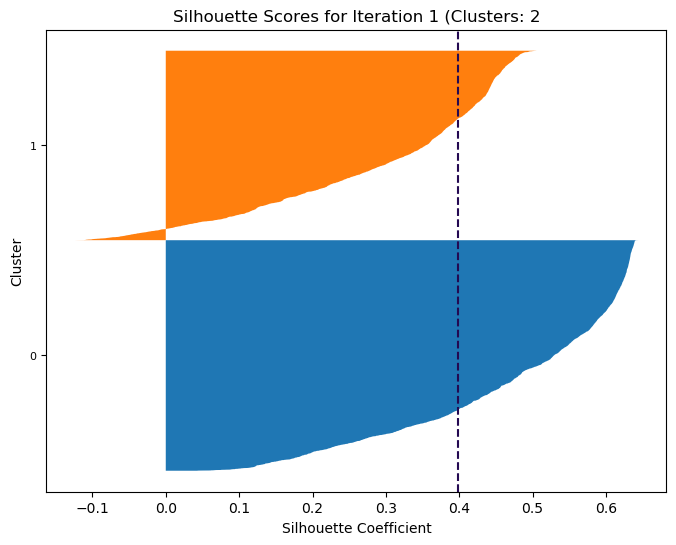

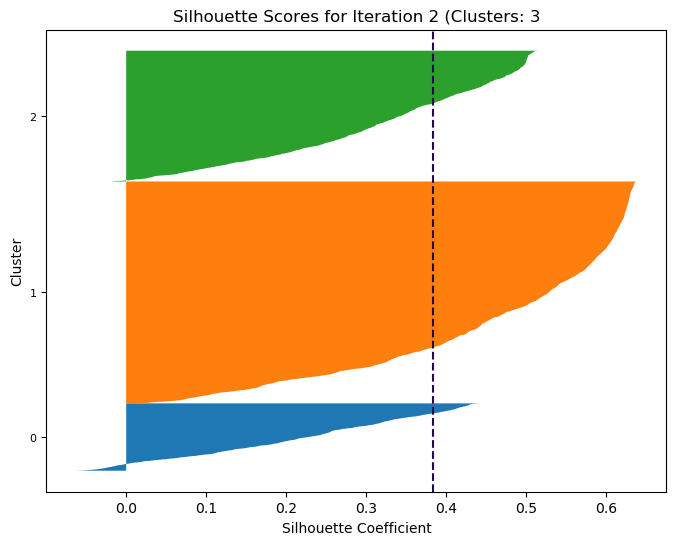

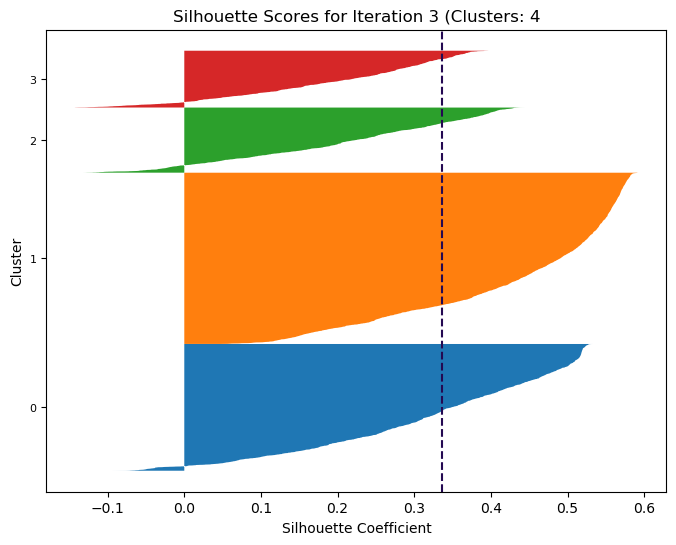

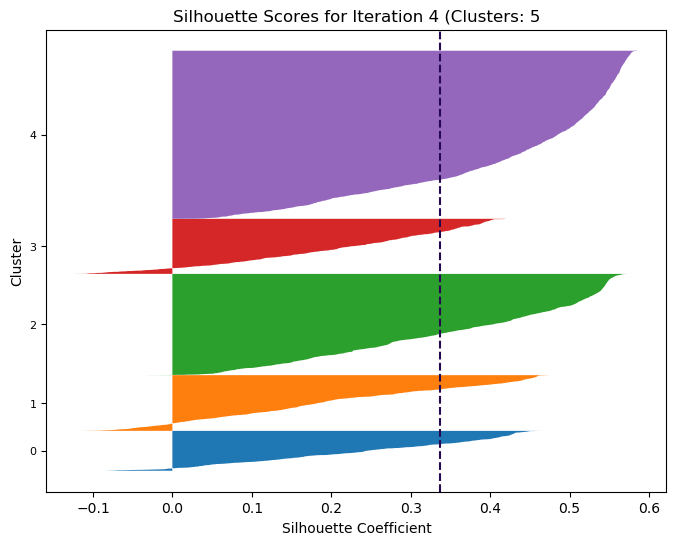

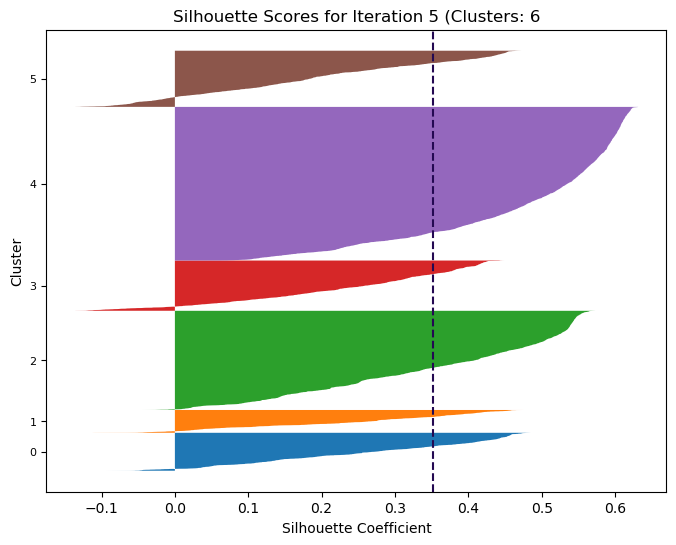

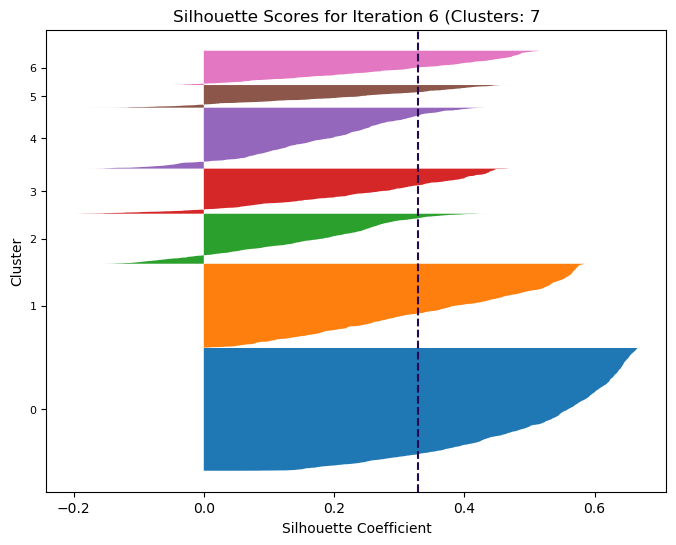

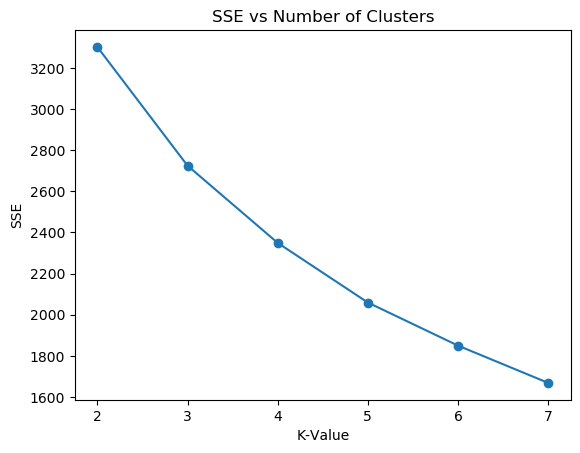

In [ ]:
for model in kmeans_iter1:
    plot_silhouette(kmeans_iter1[model])
plot_elbow_graph(kmeans_iter1)

For the KMeans modeling, it's clear from the silhouette plots and the SSE that the largest changes in the models occur between the second and third iterations, afterwards the drop in SSE becomes more constant hovering somewhere around 200-300. Additionally, as with 5 clusters there is a grouping that has a misproportionate amount of data points compared to the rest, it is not a good cluster spread. For these reasons if we proceed with KMeans, we will be using Iteration 3 containing only 4 clusters.

In [51]:
agg_clust__results1

,Algorithm,Clusters Found,Silhouette Score,n_clusters,distance_metric,linkage,distance_threshold
Iteration 1,Hierarchical Clustering,2,0.339743,2,euclidean,ward,None
Iteration 2,Hierarchical Clustering,4181,0.321189,None,euclidean,ward,0.1
Iteration 3,Hierarchical Clustering,2,0.300021,2,euclidean,average,None
Iteration 4,Hierarchical Clustering,3655,0.276041,None,euclidean,average,0.1
Iteration 5,Hierarchical Clustering,2,0.359666,2,manhattan,average,None
Iteration 6,Hierarchical Clustering,5268,0.267081,None,manhattan,average,0.1
Iteration 7,Hierarchical Clustering,2,0.553511,2,cosine,average,None
Iteration 8,Hierarchical Clustering,3,0.309297,3,euclidean,ward,None
Iteration 9,Hierarchical Clustering,3,0.356779,3,euclidean,average,None
Iteration 10,Hierarchical Clustering,3,0.29227,3,manhattan,average,None


In [87]:
dbscan_results1

,Algorithm,Clusters Found,Distance Metric,Min Samples,Epsilon,P Value,Noise (%),Silhouette Score
Iteration 1,DBSCAN,13,euclidean,5,0.2,1.5,7.58744,-0.287982
Iteration 2,DBSCAN,13,euclidean,5,0.2,3,7.58744,-0.287982
Iteration 3,DBSCAN,13,euclidean,5,0.2,4,7.58744,-0.287982
Iteration 4,DBSCAN,5,euclidean,10,0.2,1.5,10.8839,-0.0833407
Iteration 5,DBSCAN,5,euclidean,10,0.2,3,10.8839,-0.0833407
Iteration 6,DBSCAN,5,euclidean,10,0.2,4,10.8839,-0.0833407
Iteration 7,DBSCAN,3,euclidean,20,0.2,1.5,16.3594,0.00448993
Iteration 8,DBSCAN,3,euclidean,20,0.2,3,16.3594,0.00448993
Iteration 9,DBSCAN,3,euclidean,20,0.2,4,16.3594,0.00448993
Iteration 10,DBSCAN,93,manhattan,5,0.2,1.5,38.5965,-0.490354


As we can see from the results table for DBSCAN, when using Manhattan distances and an epsiilon of 0.2, our clustering is very poor. These models have large ammounts of clusters, negative  silhouette scores, and a big portion of the data is classified as noise. From this we can tell that we should exclude these models from our selection. Additionally, testing the P value, It seems to have no effect on distances other than minkowski, so if selected to proceed Minkowski disctances will be tested separately and p-values will be excluded from Euclideean and Manhattan.

For euclidean distances, as no distance threshold other than 0.2 resulted in valid clustering, we will be reducing the range scanned to be in the range of 0.2 to better identify the best model. Regarding the minimum samples used, as we increase the minimum samples the noise tends to increase, but so does the silhouete scores, as such we will be starting from min samples of 10 testing increases of 5 up to 30 to see whether the results change.

Manhattan distances on models with epsilon greater than 0.2, only the 0.4 epsilon values showed valid results. Therefore we will test epsilon in this vicinity in the next iteration. With regards to the minimum samples parameter, similar to euclidean distances, the higher sample counts tended to produce much better silhouete scorse while increasing noise slightly, we will again check every 5 within the inclusive range from 10 to 30 for this distance metric to determine the best minimum samples to use.

In [85]:
kmeans_iter1, kmeans_results1 = get_kmeans(data_t,k_range=4)

In [ ]:
def DBSCAN_breakdown(model_metrics):
    dbscan_breakdown = {}
    for model in model_metrics:
        plot_silhouette(model_metrics[model])
        n_clusters = model_metrics[f"{model}"]["Clusters Found"]
        # print("Number of Clusters: ", n_clusters)
        dbscan_breakdown[model] = {"Number of Clusters": n_clusters,
                                    "Noise": np.sum(model_metrics[model]["Labels"] == -1)}
        for n in range(n_clusters):
            dbscan_breakdown[model][f"Cluster {n}"] = np.sum(model_metrics[model]["Labels"] == n)
        
    df_dbscan = pd.DataFrame(dbscan_breakdown)
    cluster_order = [f"Cluster {n}" for n in range(max(model_metrics[model]["Clusters Found"] for model in model_metrics))]
    df_dbscan.reindex(cluster_order)
    return df_dbscan

## Final Selection

## Conclusion

In [ ]:
def label_data(chosen_model):
    labels = chosen_model["Labels"]
    # Add cluster labels to the features DataFrame
    df_labeled = df_cc_clean.copy()
    df_labeled["Cluster"] = labels
    return df_labeled
df_cc_labeled = label_data()

In [ ]:
# Plot Scatterplot of chosen features coloured by cluster

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cc_labeled, x="age",y="max heart rate",hue="Cluster",alpha=0.6,s=30)
plt.title("Patient Clusters: Age vs Max Heart Rate")
plt.xlabel("Age")
plt.ylabel("Max Heart Rate")
plt.show()
 
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cc_labeled,x="blood pressure",y="cholesterol",hue="Cluster",alpha=0.6,s=30)
plt.title("Patient Clusters: Blood Pressure vs Cholesterol")
plt.xlabel("Blood Pressure")
plt.ylabel("Cholesterol")
plt.show()
 
plt.figure(figsize=(10, 6)) 
sns.scatterplot(data=df_cc_labeled,x="blood pressure",y="chest pain type",hue="Cluster",alpha=0.6,s=30) 
plt.title("Patient Clusters: Blood Pressure vs Chest Pain Type")
plt.xlabel("Blood Pressure")
plt.ylabel("Chest Pain Type")
plt.show()

## Scatter Plot Obsevations


## Cluster Breakdowns

In [ ]:
def plot_cluster_distribution(df_cc_labeled):
    # Plot Histogram of chosen model cluster breakdown
    plt.figure(figsize=(7, 5))
    sns.countplot(data=df_cc_labeled, x="Cluster", palette="tab10")
    plt.title(f"Iteration 1: Cluster Distribution")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Customers")
    for i, count in df_cc_labeled["Cluster"].value_counts().sort_index().items():
        plt.text(i+1, count + 1, str(count), ha="center")
    plt.show()

def model_breakdown(chosen_model,df_labeled):
    # Creates a dataframe for each cluster and assigns them to a variable
    clusters_dfs = dict()
    for i in range(min(chosen_model["Labels"]),chosen_model["Clusters Found"]):
        if i == -1:
            noise_df = df_labeled[df_labeled["Cluster"] == i]
        else:
            clusters_dfs[i] = df_labeled[df_labeled["Cluster"] == i]

## Final Propositions

## Acknowledgment of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  
Data Preprocessing: Sebastian Levy & Idongesit Orok  
Data Observations: Sebastian Levy, Idongesit Orok, Miracle Okojie  
Data Visualizations: Idongesit Orok  
Data Scaling and PCA: Sebastian Levy  
KMeans Modeling: Sebastian Levy  
Hierarchical Modeling: Sebastian Levy  
DBSCAN Modeling: Sebastian Levy  
Model Selection:  

We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.